# Load the Data

In [49]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
import kagglehub
path = kagglehub.dataset_download("behrad3d/nasa-cmaps")

Using Colab cache for faster access to the 'nasa-cmaps' dataset.


In [32]:
data=pd.read_csv(path+"/CMaps/train_FD001.txt",sep=r"\s+",header=None)
test=pd.read_csv(path+"/CMaps/test_FD001.txt",sep=r"\s+",header=None)
RUL=pd.read_csv(path+"/CMaps/RUL_FD001.txt",sep=r"\s+",header=None)
data.shape,test.shape,RUL.shape

((20631, 26), (13096, 26), (100, 1))

In [33]:
data.head(3)

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442


# Making Data Understandable

In [35]:
# Naming Numerical cols to understandable forms
cols=(['engine_id','cycle'] + [f'operation_setttings {i}' for i in range(1,4)] + [f'sensor {i}' for i in range(1,22)])
data.columns=cols
test.columns=cols
data.head(3)

,engine_id,cycle,operation_setttings 1,operation_setttings 2,operation_setttings 3,sensor 1,sensor 2,sensor 3,sensor 4,sensor 5,...,sensor 12,sensor 13,sensor 14,sensor 15,sensor 16,sensor 17,sensor 18,sensor 19,sensor 20,sensor 21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442


# Understanding Data-EDA

In [47]:
engine_lifes=data.groupby('engine_id')['cycle'].max()
# total number of engines
print(data['engine_id'].nunique())
# Avg lifetime
print("AVerage life cycle",engine_lifes.mean())
# Max life cycle
print("MAx life cycle",engine_lifes.max())
# min life cycle
print("Lowest life cycle",engine_lifes.min())

100
AVerage life cycle 206.31
MAx life cycle 362
Lowest life cycle 128


In [48]:
engine_lifes.head(10)

,cycle
engine_id,
1,192
2,287
3,179
4,189
5,269
6,188
7,259
8,150
9,201


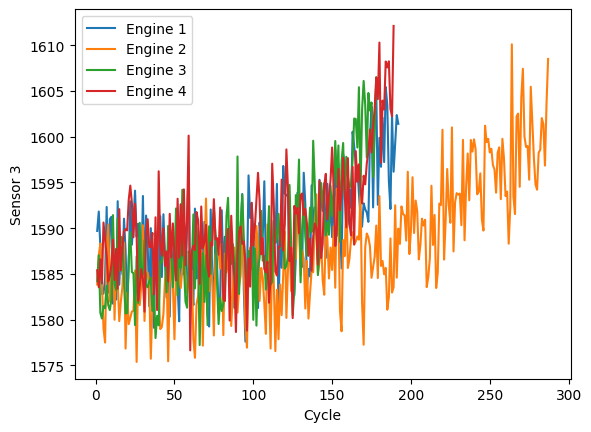

In [54]:
for i in range(1,5):
  engine=data[data['engine_id']==i]
  plt.plot(
      engine['cycle'],
      engine['sensor 3'],
      label=f'Engine {i}'
      )
plt.xlabel('Cycle')
plt.ylabel('Sensor 3')
plt.legend()
plt.show()

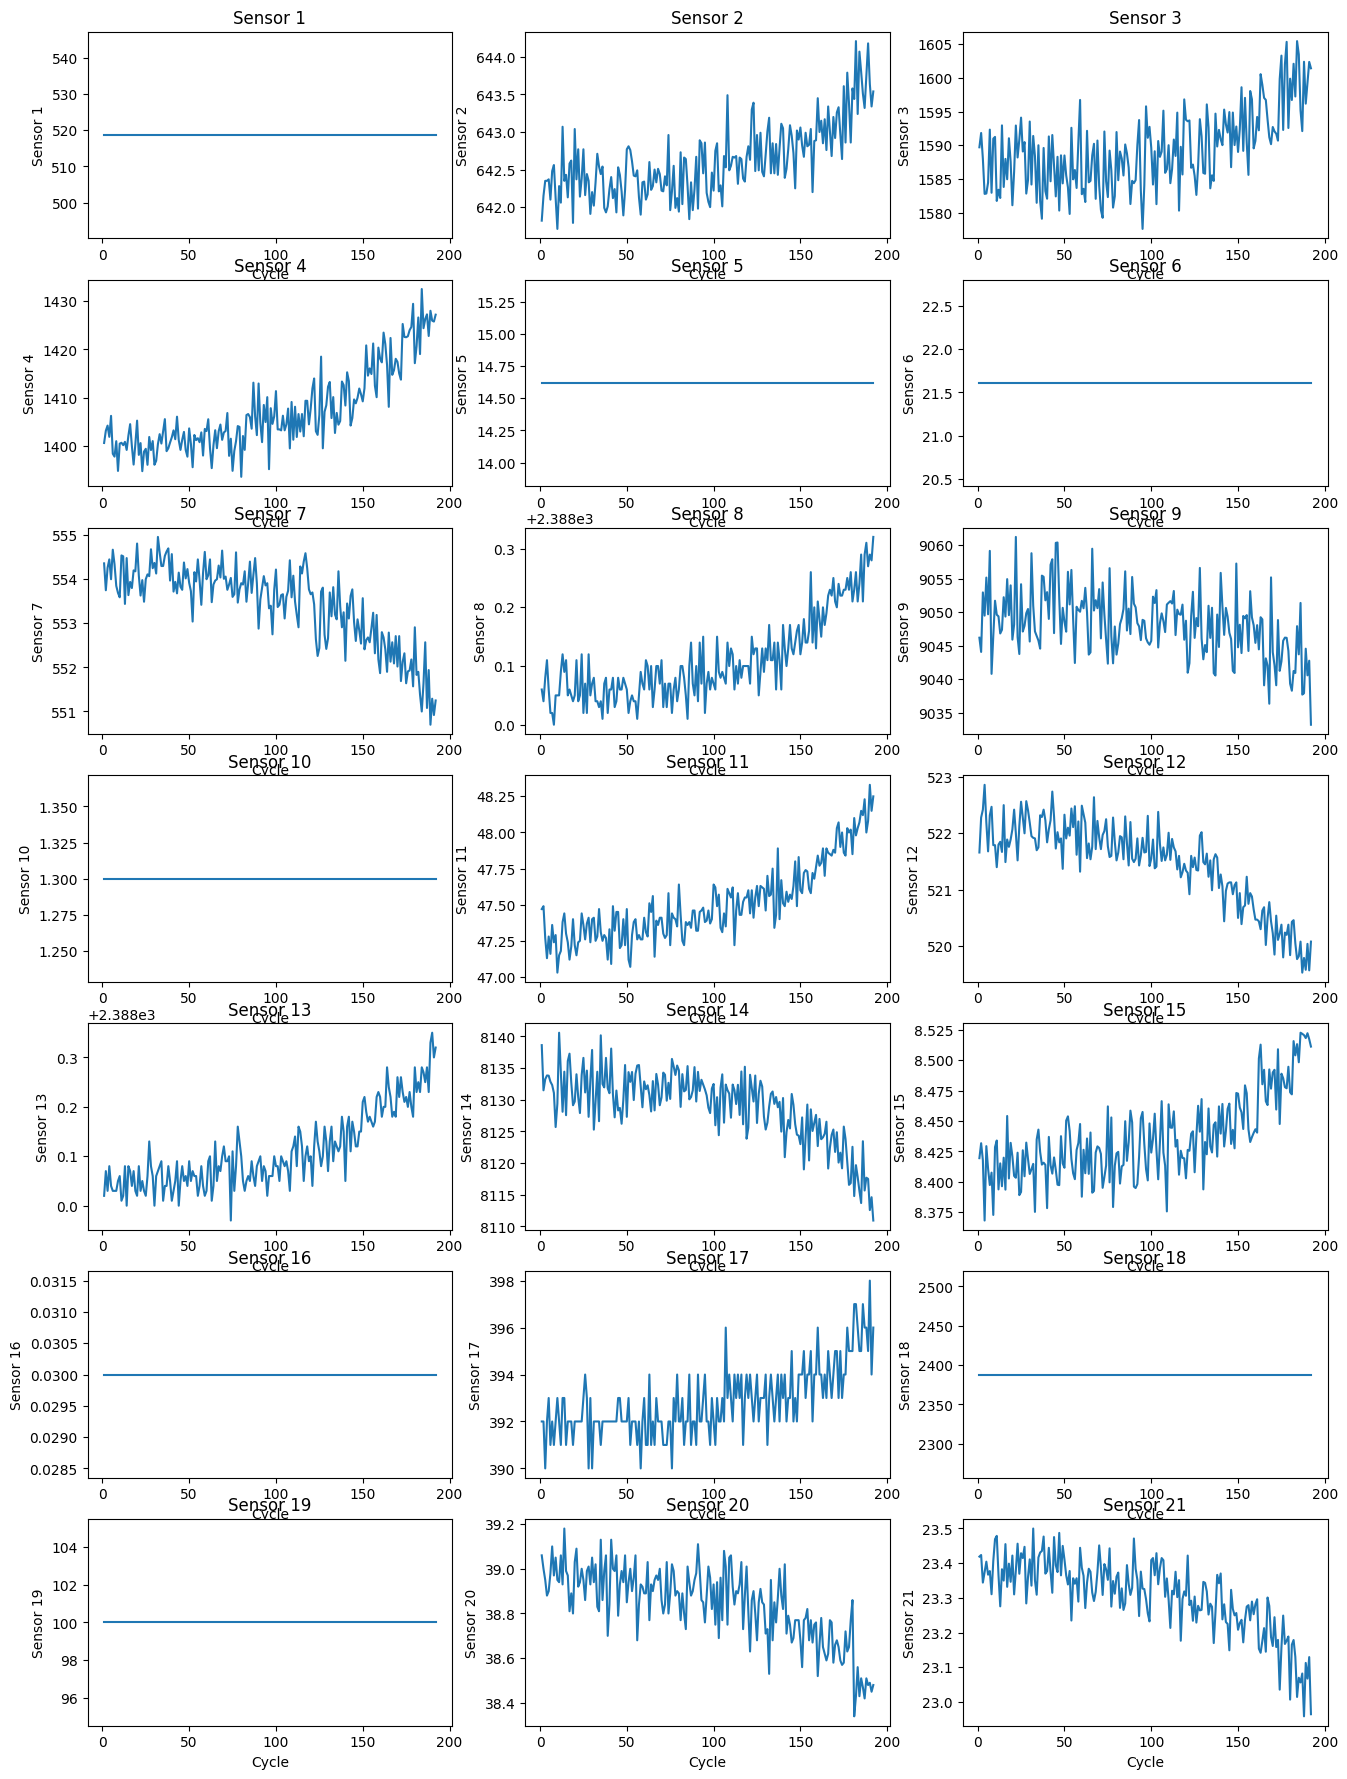

In [57]:
# Checking for every sensor using one engine
engine=data[data['engine_id']==1]
fig,axes=plt.subplots(nrows=7,ncols=3,figsize=(16,22))
for i in range(1,22):
  ax=axes[(i-1)//3,(i-1)%3]
  ax.plot(engine['cycle'],engine[f'sensor {i}'])
  ax.set_title(f'Sensor {i}')
  ax.set_xlabel('Cycle')
  ax.set_ylabel(f'Sensor {i}')

We can see that no every sensor value is increasing but some are stangnant and some are decreasing

In [63]:
data.isnull().sum()

,0
engine_id,0
cycle,0
operation_setttings 1,0
operation_setttings 2,0
operation_setttings 3,0
sensor 1,0
sensor 2,0
sensor 3,0
sensor 4,0
sensor 5,0


In [64]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   engine_id              20631 non-null  int64  
 1   cycle                  20631 non-null  int64  
 2   operation_setttings 1  20631 non-null  float64
 3   operation_setttings 2  20631 non-null  float64
 4   operation_setttings 3  20631 non-null  float64
 5   sensor 1               20631 non-null  float64
 6   sensor 2               20631 non-null  float64
 7   sensor 3               20631 non-null  float64
 8   sensor 4               20631 non-null  float64
 9   sensor 5               20631 non-null  float64
 10  sensor 6               20631 non-null  float64
 11  sensor 7               20631 non-null  float64
 12  sensor 8               20631 non-null  float64
 13  sensor 9               20631 non-null  float64
 14  sensor 10              20631 non-null  float64
 15  se